# 03. Model Training & Evaluation

## Overview
This notebook serves as the main entry point for:
1.  **Verifying the Hardware** (GPU availability).
2.  **Training the ResNet50 Model or efficientnet_b3** (training pipeline).
3.  **Evaluating Performance** using professional diagnostic plots (Confusion Matrix, ROC, Reliability Curves).

## Objectives
-   Confirm CUDA acceleration is active.
-   Train the model on the processed dataset.
-   Assess generalization performance on the validation set.
-   Visualize class-wise metrics and prediction confidence.

In [12]:
# --- Imports ---
%load_ext autoreload
%autoreload 2

import os
import shutil
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Add project root to path
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.config import (
    DATA_DIR,
    MODELS_DIR,
    PROCESSED_DATA_DIR,
    PROJECT_ROOT,
    QUALITY_THRESHOLD,
    REPORTS_DIR,
)
from src.utils.logger import get_logger
from src.visualization.eda import (
    load_and_show_error_samples,
    print_classification_summary,
)
from src.visualization.plots import (
    plot_binary_classification_metrics,
    plot_calibration_curves,
    plot_confidence_abstention_panel,
    plot_confusion_matrix_pair,
    plot_error_distribution,
    plot_learning_curves,
    plot_model_diagnostics,
    plot_performance_vs_quality,
    set_plot_style,
)

# --- Configuration ---
set_plot_style()
logger = get_logger(__name__)

logger.info(f"Project Root: {PROJECT_ROOT}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
2026-02-17 11:18:15,569 - __main__ - INFO - Project Root: C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection
2026-02-17 11:18:15,569 - __main__ - INFO - Project Root: C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection


In [13]:
# 2. Hardware Verification
logger.info(f"PyTorch Version: {torch.__version__}")

if torch.cuda.is_available():
    device_name = torch.cuda.get_device_name(0)
    device_count = torch.cuda.device_count()
    logger.info(f"GPU available: {device_name} (x{device_count}), CUDA {torch.version.cuda}")
else:
    logger.warning("GPU not detected. Training will be extremely slow on CPU.")

2026-02-17 11:18:15,674 - __main__ - INFO - PyTorch Version: 2.7.1+cu118
2026-02-17 11:18:15,674 - __main__ - INFO - PyTorch Version: 2.7.1+cu118
2026-02-17 11:18:15,682 - __main__ - INFO - GPU available: NVIDIA RTX 2000 Ada Generation Laptop GPU (x1), CUDA 11.8
2026-02-17 11:18:15,682 - __main__ - INFO - GPU available: NVIDIA RTX 2000 Ada Generation Laptop GPU (x1), CUDA 11.8


In [14]:
# 3. Model Selection & Execution
# --------------------------------------------------------------------------
MODEL_NAME = "efficientnet_b3"  # 'efficientnet_b3' 'resnet50'
USE_QUALITY_FILTER = True
FORCE_RERUN = False
# --------------------------------------------------------------------------

logger.info(f"Selected Model: {MODEL_NAME}")
if USE_QUALITY_FILTER:
    logger.info(f"Quality Filter: ON (Threshold: {QUALITY_THRESHOLD})")
    suffix = "_filtered"
    quality_arg = f"--min-quality {QUALITY_THRESHOLD}"
else:
    logger.info("Quality Filter: OFF (Evaluating on ALL images)")
    suffix = ""
    quality_arg = "--min-quality 0.0"

HISTORY_PATH = REPORTS_DIR / f"history_{MODEL_NAME}.joblib"
PREDICTIONS_PATH = REPORTS_DIR / f"predictions_{MODEL_NAME}{suffix}.csv"

if PREDICTIONS_PATH.exists() and not FORCE_RERUN:
    logger.info(f"Found existing results: {PREDICTIONS_PATH.name}")
else:
    if FORCE_RERUN:
        logger.info("Force Rerun Enabled. Recomputing predictions...")
    else:
        logger.info("Predictions not found. Checking for weights...")

    weights_path = MODELS_DIR / f"{MODEL_NAME}_best.pth"

    if weights_path.exists():
        logger.info(f"Found trained weights at {weights_path}")
        logger.info("Running inference generation...")

        os.environ["PYTHONPATH"] = str(PROJECT_ROOT)

        !python -m src.models.train_model --model {MODEL_NAME} --evaluate --cached --num-workers 4 --batch-size 8 {quality_arg}

        standard_pred_path = REPORTS_DIR / f"predictions_{MODEL_NAME}.csv"
        if USE_QUALITY_FILTER and standard_pred_path.exists():
            shutil.move(str(standard_pred_path), str(PREDICTIONS_PATH))
            logger.info(f"Renamed output to {PREDICTIONS_PATH.name}")

    else:
        logger.info("No trained weights found. Starting FULL TRAINING...")
        os.environ["PYTHONPATH"] = str(PROJECT_ROOT)
        !python -m src.models.train_model --model {MODEL_NAME} --cached --num-workers 4 --batch-size 8 {quality_arg}

    if PREDICTIONS_PATH.exists():
        logger.info("Process finished successfully.")

2026-02-17 11:18:15,777 - __main__ - INFO - Selected Model: efficientnet_b3
2026-02-17 11:18:15,777 - __main__ - INFO - Selected Model: efficientnet_b3
2026-02-17 11:18:15,778 - __main__ - INFO - Quality Filter: ON (Threshold: 0.0583)
2026-02-17 11:18:15,778 - __main__ - INFO - Quality Filter: ON (Threshold: 0.0583)
2026-02-17 11:18:15,780 - __main__ - INFO - Found existing results: predictions_efficientnet_b3_filtered.csv
2026-02-17 11:18:15,780 - __main__ - INFO - Found existing results: predictions_efficientnet_b3_filtered.csv


2026-02-17 11:18:15,863 - __main__ - INFO - Loading Artifacts for: efficientnet_b3...
2026-02-17 11:18:15,863 - __main__ - INFO - Loading Artifacts for: efficientnet_b3...
2026-02-17 11:18:15,865 - __main__ - INFO - Training History Loaded. Keys: ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_kappa']
2026-02-17 11:18:15,865 - __main__ - INFO - Training History Loaded. Keys: ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_kappa']
2026-02-17 11:18:15,867 - __main__ - INFO - Best Val Loss: 0.8362 (Epoch 9) | Best Val Kappa: 0.7991 (Epoch 20)
2026-02-17 11:18:15,867 - __main__ - INFO - Best Val Loss: 0.8362 (Epoch 9) | Best Val Kappa: 0.7991 (Epoch 20)
2026-02-17 11:18:16,228 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\evaluation\efficientnet_b3_learning_curves.png
2026-02-17 11:18:16,228 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_im

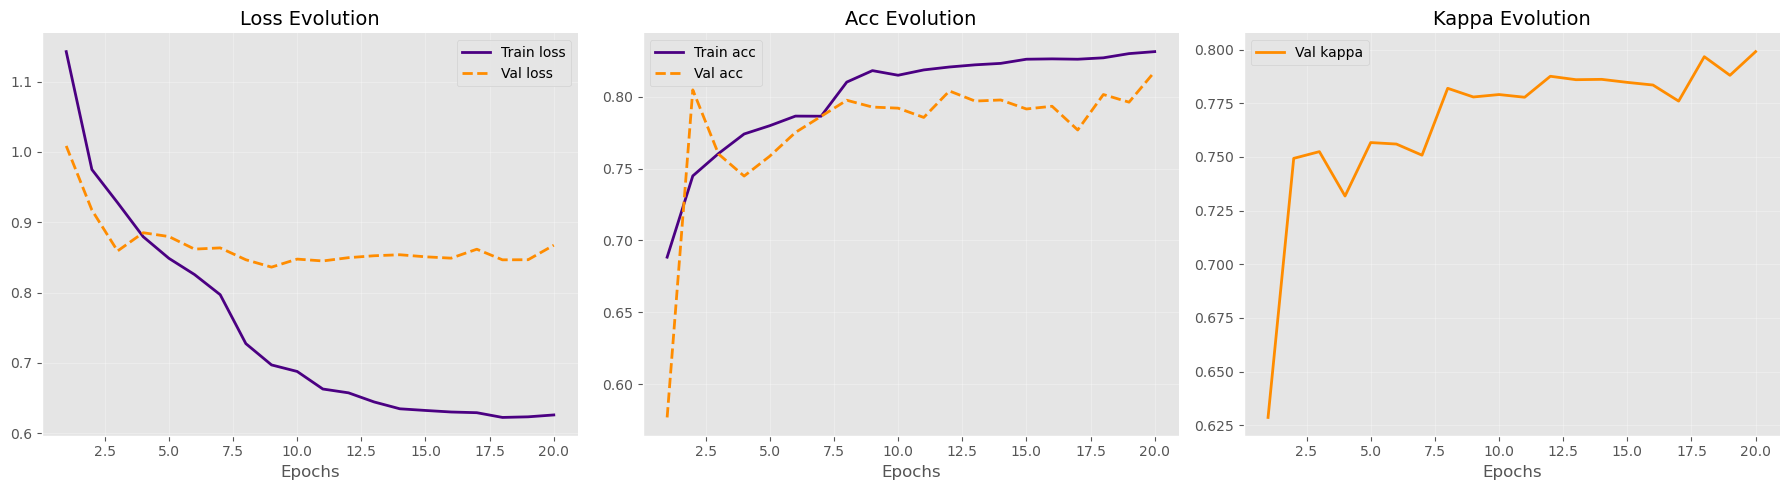

2026-02-17 11:18:16,385 - __main__ - INFO - Predictions Loaded. Shape: (5006, 8)
2026-02-17 11:18:16,385 - __main__ - INFO - Predictions Loaded. Shape: (5006, 8)


,image_name,true,pred,prob_0,prob_1,prob_2,prob_3,prob_4
0,30_left,1,0,0.491523,0.437470,0.067634,0.003118,0.000255
1,30_right,2,0,0.822458,0.163797,0.013287,0.000441,0.000017
2,46_left,0,0,0.623307,0.373438,0.003198,0.000037,0.000020
3,46_right,0,0,0.697980,0.275846,0.021280,0.003536,0.001358
4,49_left,0,0,0.609233,0.124385,0.262904,0.002280,0.001199


In [15]:
# 4. Load Artifacts & Plot Learning Curves

logger.info(f"Loading Artifacts for: {MODEL_NAME}...")

if HISTORY_PATH.exists():
    history = joblib.load(HISTORY_PATH)
    logger.info(f"Training History Loaded. Keys: {list(history.keys())}")

    best_loss_idx = np.argmin(history["val_loss"])
    best_kappa_idx = np.argmax(history.get("val_kappa", [-1]))

    logger.info(
        f"Best Val Loss: {history['val_loss'][best_loss_idx]:.4f} (Epoch {best_loss_idx + 1}) | "
        f"Best Val Kappa: {history.get('val_kappa', [0])[best_kappa_idx]:.4f} (Epoch {best_kappa_idx + 1})"
    )

    plot_learning_curves(history, save_folder="evaluation", title_prefix=f"{MODEL_NAME}_")
    plt.show()
else:
    logger.error("History file not found.")

if PREDICTIONS_PATH.exists():
    preds_df = pd.read_csv(PREDICTIONS_PATH)
    logger.info(f"Predictions Loaded. Shape: {preds_df.shape}")
    display(preds_df.head())
else:
    logger.error("Predictions file not found.")

2026-02-17 11:18:16,494 - src.visualization.eda - INFO - 
--- Multi-Class Classification Analysis (5 Grades) ---
Overall Accuracy: 0.8272
Balanced Accuracy: 0.6908
Quadratic Weighted Kappa (QWK): 0.8358 (Key Clinical Metric)
F1-Score (Macro): 0.6588
F1-Score (Weighted): 0.8396
2026-02-17 11:18:16,494 - src.visualization.eda - INFO - 
--- Multi-Class Classification Analysis (5 Grades) ---
Overall Accuracy: 0.8272
Balanced Accuracy: 0.6908
Quadratic Weighted Kappa (QWK): 0.8358 (Key Clinical Metric)
F1-Score (Macro): 0.6588
F1-Score (Weighted): 0.8396
2026-02-17 11:18:16,494 - src.visualization.eda - INFO - 
Per-Class Metrics:
               precision    recall  f1-score   support

        No DR       0.94      0.89      0.92      3710
         Mild       0.32      0.55      0.40       343
     Moderate       0.77      0.66      0.71       751
       Severe       0.48      0.73      0.58       126
Proliferative       0.76      0.62      0.68        76

     accuracy                      

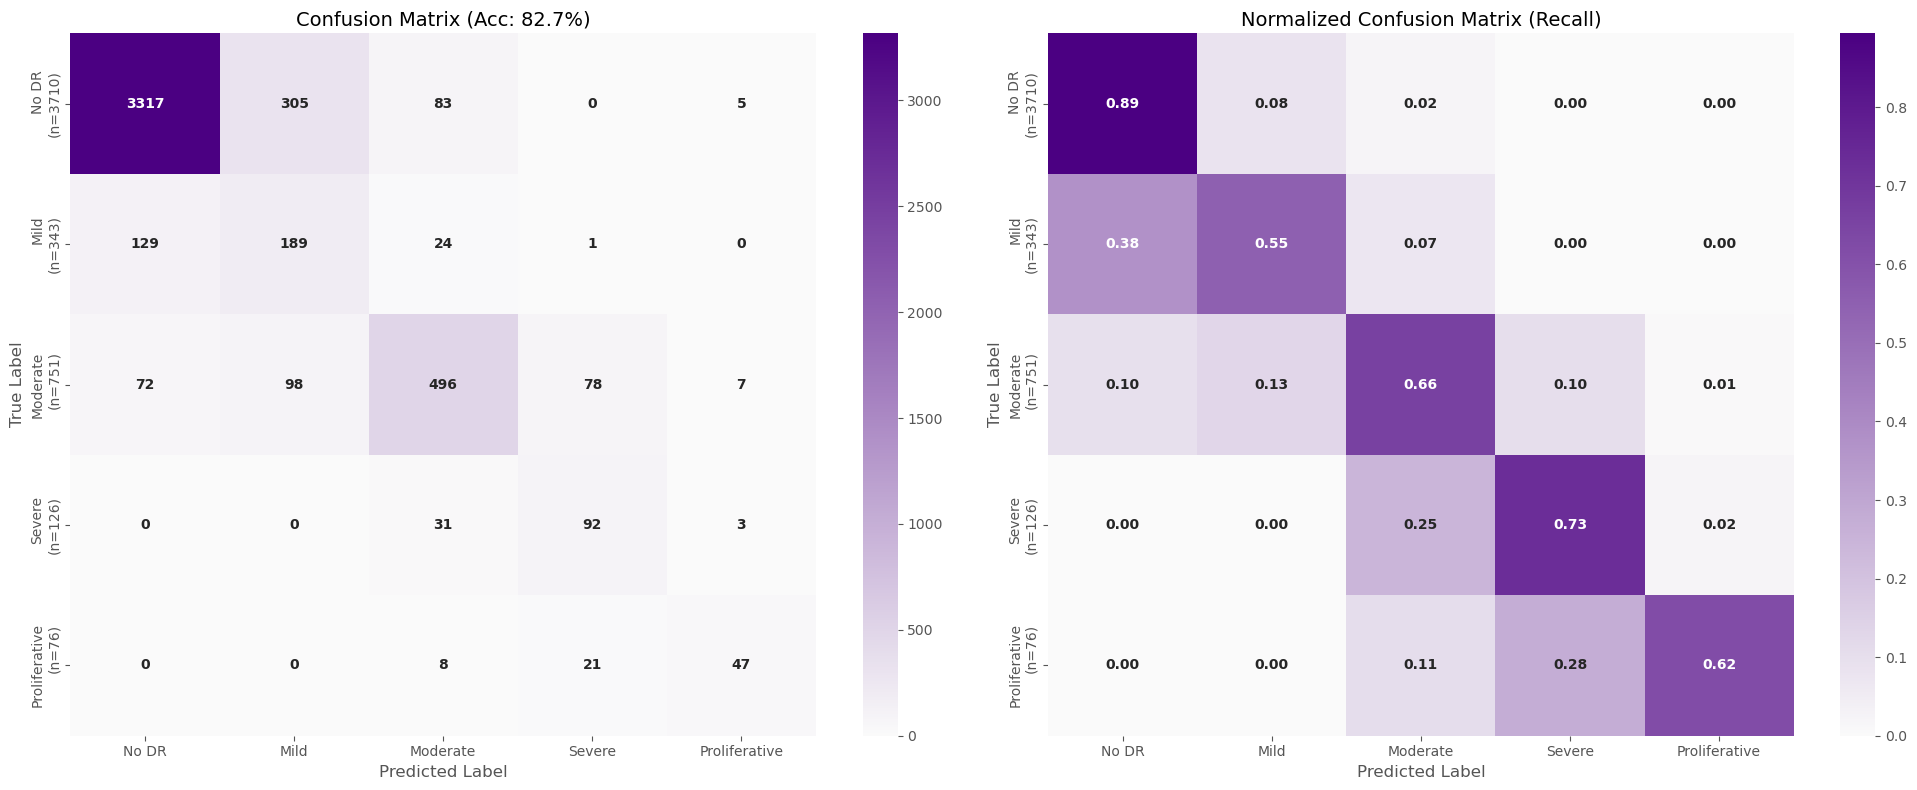

In [16]:
# 5. Confusion Matrix & Detailed Metrics

if PREDICTIONS_PATH.exists():
    y_true = preds_df["true"]
    y_pred = preds_df["pred"]

    # Print scalar metrics and classification report
    print_classification_summary(y_true, y_pred)

    # Confusion matrices (Count + Normalized)
    plot_confusion_matrix_pair(
        y_true,
        y_pred,
        title_prefix=f"{MODEL_NAME}_",
        save_folder="evaluation",
    )
    plt.show()

2026-02-17 11:18:17,158 - __main__ - INFO - Loading predictions from: C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\predictions_efficientnet_b3_filtered.csv
2026-02-17 11:18:17,158 - __main__ - INFO - Loading predictions from: C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\predictions_efficientnet_b3_filtered.csv
2026-02-17 11:18:17,172 - __main__ - INFO - Columns: ['image_name', 'true', 'pred', 'prob_0', 'prob_1', 'prob_2', 'prob_3', 'prob_4']
2026-02-17 11:18:17,172 - __main__ - INFO - Columns: ['image_name', 'true', 'pred', 'prob_0', 'prob_1', 'prob_2', 'prob_3', 'prob_4']
2026-02-17 11:18:17,259 - matplotlib.category - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-02-17 11:18:17,259 - matplotlib.category - INFO - Using categorical units to plot a li

c:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\src\visualization\plots.py:343: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  for i in range(n_classes):


2026-02-17 11:18:17,673 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\evaluation\efficientnet_b3_model_diagnostics.png
2026-02-17 11:18:17,673 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\evaluation\efficientnet_b3_model_diagnostics.png


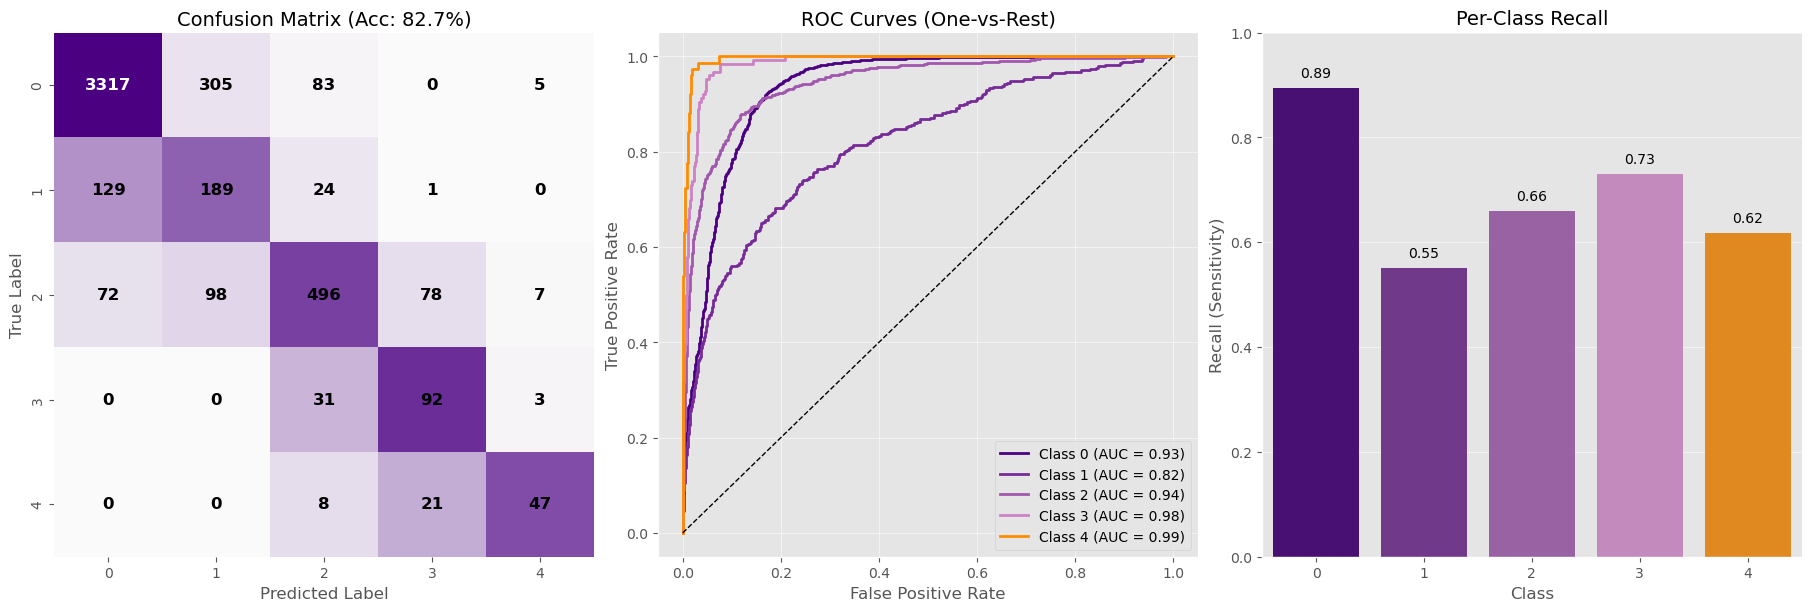

In [17]:
# 6. Diagnostic Panel (Confusion Matrix & ROC)

if PREDICTIONS_PATH.exists():
    logger.info(f"Loading predictions from: {PREDICTIONS_PATH}")
    results_df = pd.read_csv(PREDICTIONS_PATH)

    # Ensure columns match expected names
    logger.info(f"Columns: {results_df.columns.tolist()}")

    # Generate Diagnostics
    plot_model_diagnostics(results_df, n_classes=5, save_folder="evaluation", title_prefix=f"{MODEL_NAME}_")
    plt.show()
else:
    logger.warning(f"Predictions file not found at {PREDICTIONS_PATH}")

2026-02-17 11:18:18,327 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\evaluation\efficientnet_b3_confidence_analysis.png
2026-02-17 11:18:18,327 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\evaluation\efficientnet_b3_confidence_analysis.png


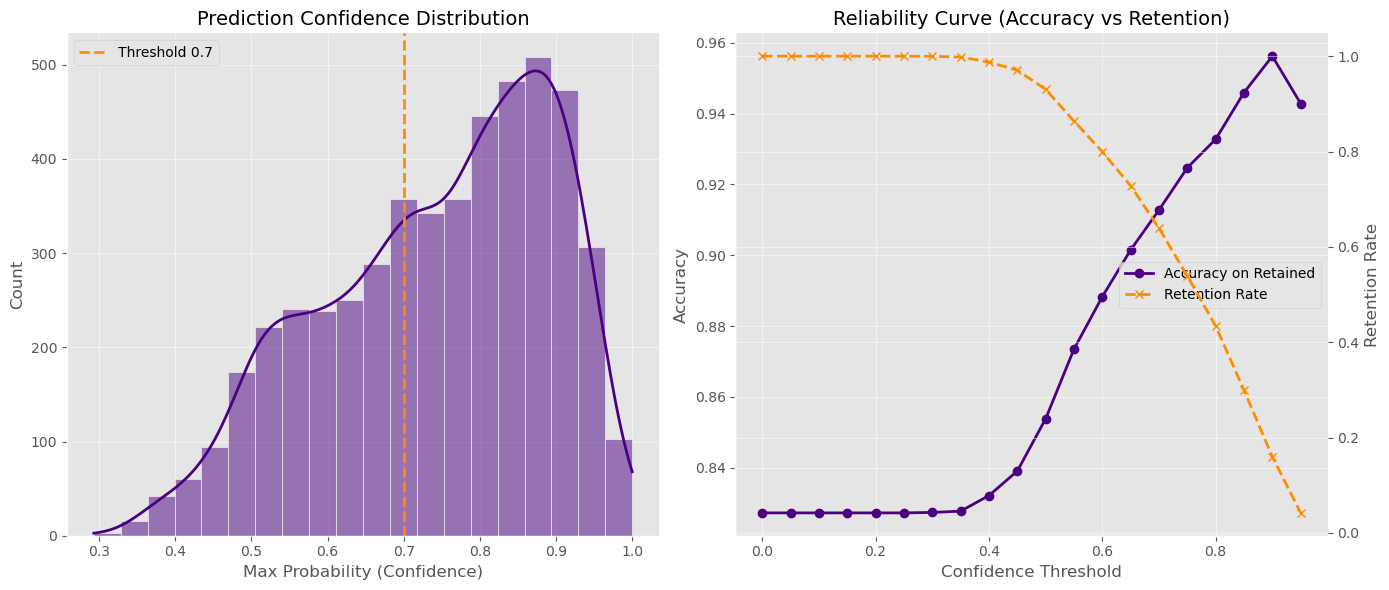

In [18]:
# 7. Reliability & Abstention Analysis

if PREDICTIONS_PATH.exists():
    plot_confidence_abstention_panel(
        results_df, confidence_threshold=0.7, save_folder="evaluation", title_prefix=f"{MODEL_NAME}_"
    )
    plt.show()

2026-02-17 11:18:18,868 - src.visualization.eda - INFO - Visualizing Error Cases...
2026-02-17 11:18:18,868 - src.visualization.eda - INFO - Visualizing Error Cases...
2026-02-17 11:18:22,168 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\evaluation\efficientnet_b3_failure_analysis.png
2026-02-17 11:18:22,168 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\evaluation\efficientnet_b3_failure_analysis.png


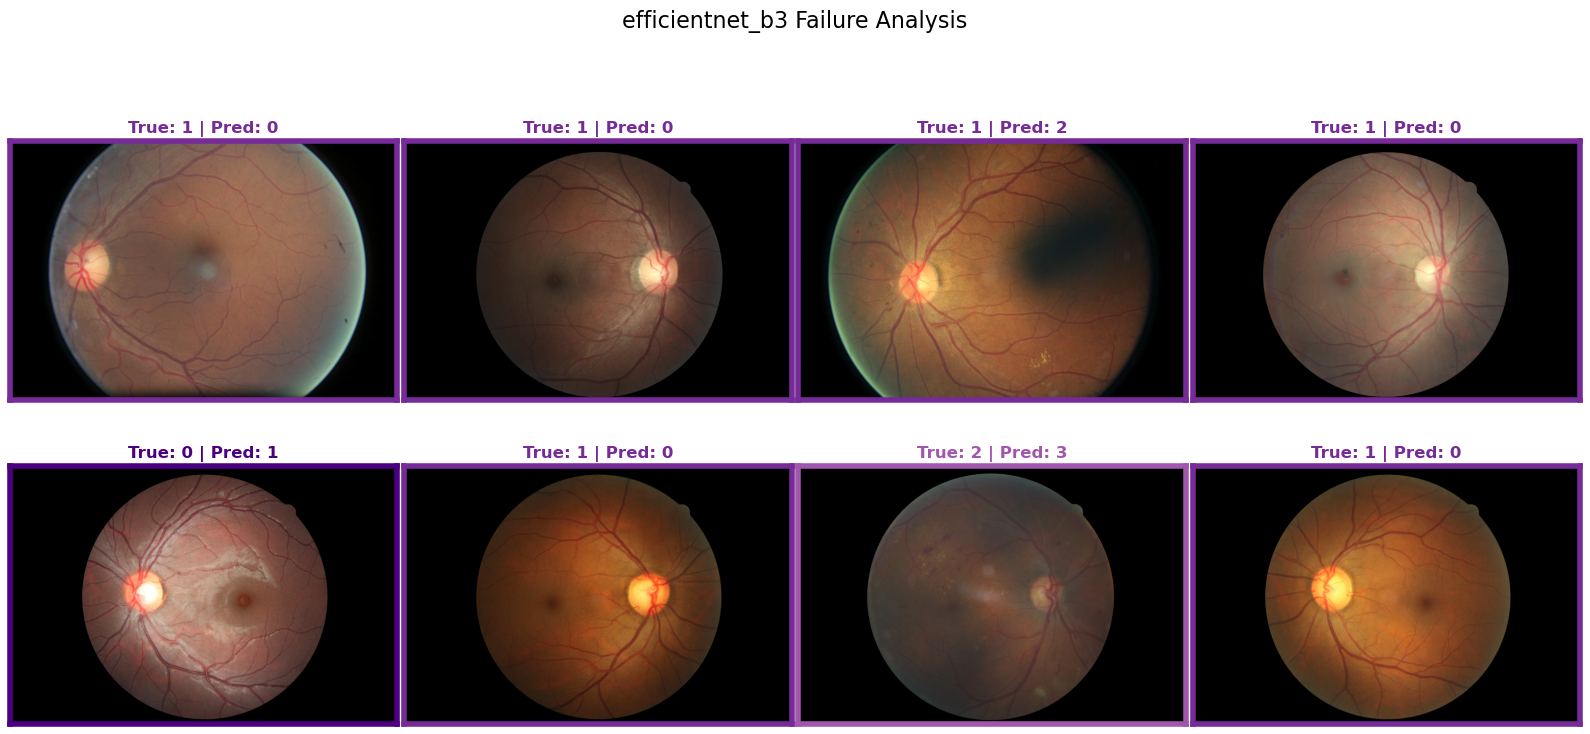

In [19]:
# 8. Sample Predictions Audit

if PREDICTIONS_PATH.exists() and "image_name" in results_df.columns:
    load_and_show_error_samples(results_df, DATA_DIR, model_name=MODEL_NAME, save_folder="evaluation")

## 9. Disease Screening Performance (Binary Classification)

In a clinical setting, the most critical decision is often **referral**: Should this patient see a specialist?
This corresponds to a binary classification task: **Healthy (No DR)** vs. **Diseased (Mild+Moderate+Severe+Proliferative)**.

We evaluate the model's ability to distinguish between these two groups.

2026-02-17 11:18:24,512 - src.visualization.plots - INFO - --- Binary Classification Analysis (Healthy vs. Diseased) ---
2026-02-17 11:18:24,512 - src.visualization.plots - INFO - --- Binary Classification Analysis (Healthy vs. Diseased) ---
2026-02-17 11:18:24,520 - src.visualization.plots - INFO - Binary Accuracy: 0.8813
2026-02-17 11:18:24,520 - src.visualization.plots - INFO - Binary Accuracy: 0.8813
2026-02-17 11:18:24,523 - src.visualization.plots - INFO - Sensitivity (Recall): 0.8449 (Ability to detect disease)
2026-02-17 11:18:24,523 - src.visualization.plots - INFO - Sensitivity (Recall): 0.8449 (Ability to detect disease)
2026-02-17 11:18:24,523 - src.visualization.plots - INFO - Specificity: 0.8941 (Ability to confirm health)
2026-02-17 11:18:24,523 - src.visualization.plots - INFO - Specificity: 0.8941 (Ability to confirm health)
2026-02-17 11:18:24,524 - src.visualization.plots - INFO - Precision: 0.7359
2026-02-17 11:18:24,524 - src.visualization.plots - INFO - Precision:

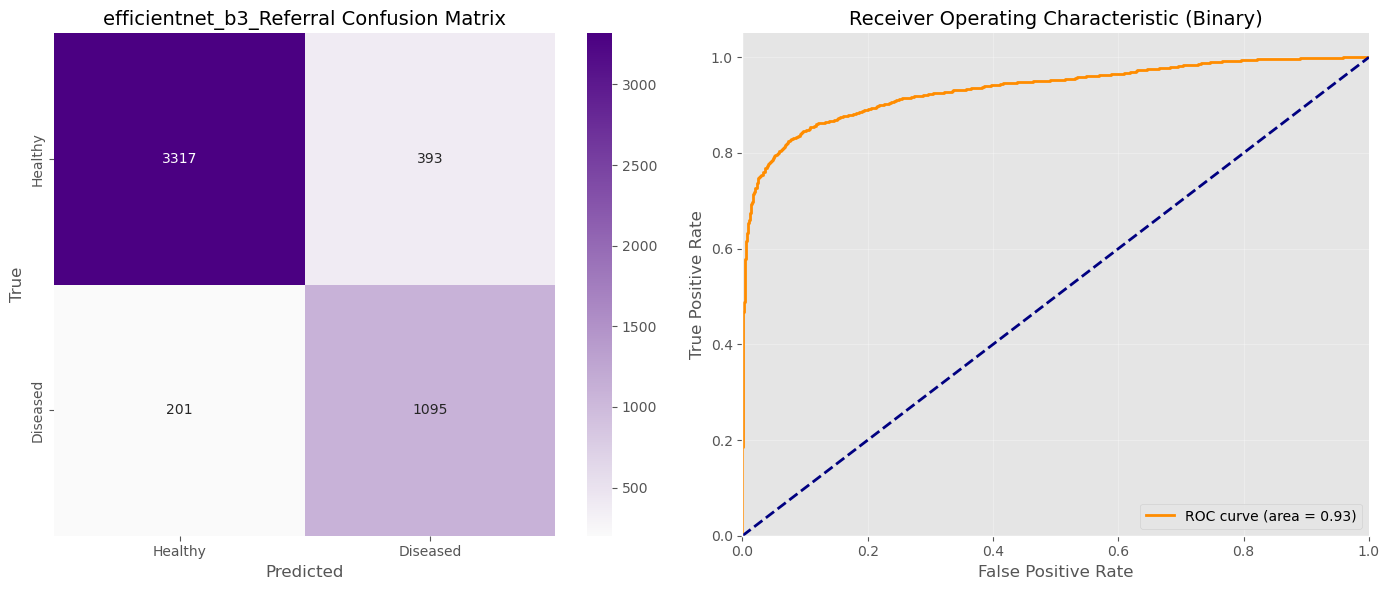

In [20]:
# 9. Disease Screening Performance (Binary Classification)

plot_binary_classification_metrics(results_df, save_folder="evaluation", title_prefix=f"{MODEL_NAME}_")
plt.show()

## 10. Reliability Metrics
We dive deeper into **how** predictions fail.
1. **Calibration**: Does a 90% confidence score actually mean 90% accuracy?
2. **Error Distribution**: Are errors small (e.g. Mild vs Moderate) or catastrophic (Healthy vs Proliferative)?

2026-02-17 11:18:25,409 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\evaluation\efficientnet_b3_calibration_curves.png
2026-02-17 11:18:25,409 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\evaluation\efficientnet_b3_calibration_curves.png


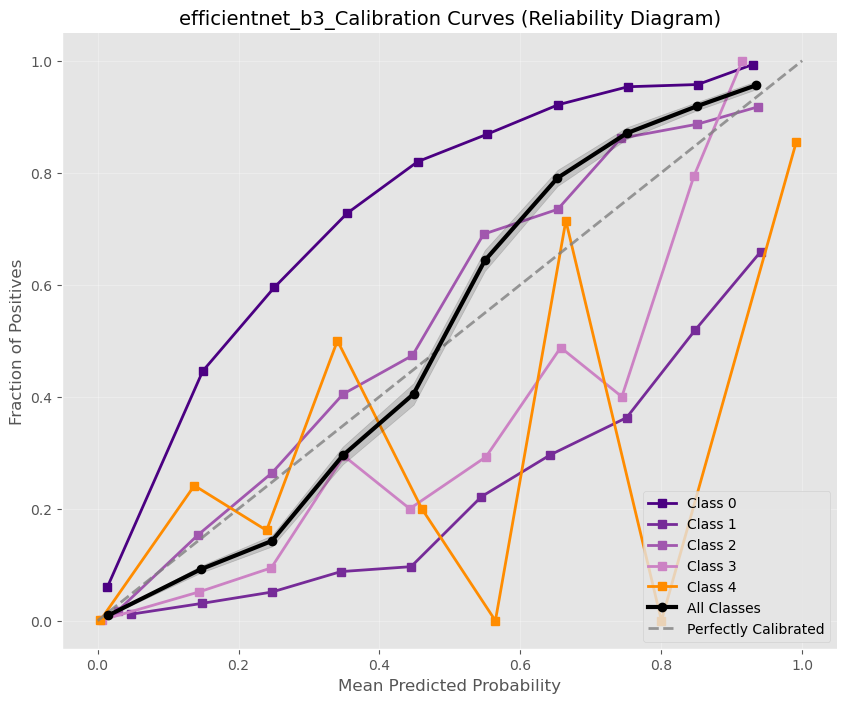

2026-02-17 11:18:25,507 - matplotlib.category - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-02-17 11:18:25,507 - matplotlib.category - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-02-17 11:18:25,507 - matplotlib.category - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-02-17 11:18:25,507 - matplotlib.category - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-02-17 11:18:25,

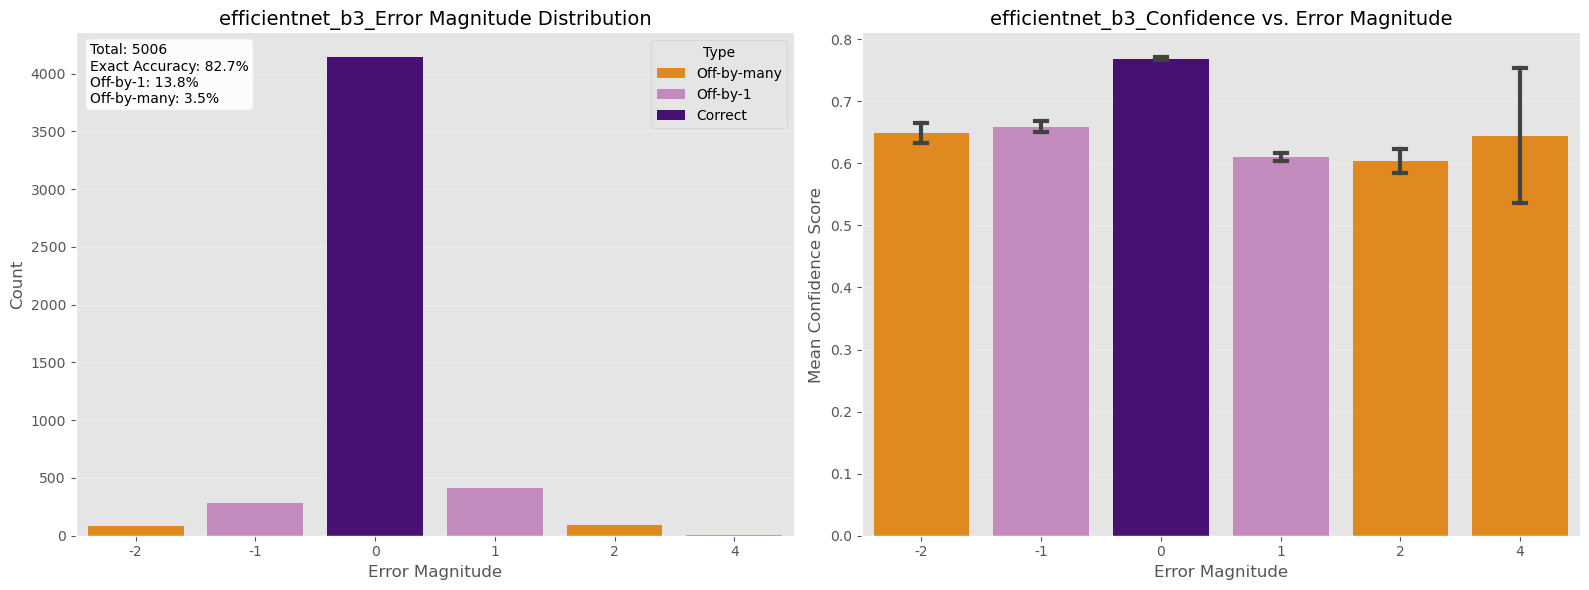

In [21]:
# 10. Calibration & Error Analysis
prob_cols = [c for c in results_df.columns if c.startswith("prob_")]
prob_matrix = results_df[prob_cols].values

# Calibration Curves (Reliability Diagram)
plot_calibration_curves(results_df["true"].values, prob_matrix, save_folder="evaluation", title_prefix=f"{MODEL_NAME}_")
plt.show()

# Error Magnitude & Confidence Analysis
confidences = prob_matrix.max(axis=1)
plot_error_distribution(
    results_df["true"].values,
    results_df["pred"].values,
    confidences=confidences,
    save_folder="evaluation",
    title_prefix=f"{MODEL_NAME}_",
)
plt.show()

## 11. Performance vs. Image Quality
We verify if model performance degrades on lower quality images (blur, artifacts).
We use **Vessel Density** (extracted during preprocessing) as a proxy for image quality.

2026-02-17 11:18:26,073 - src.visualization.plots - INFO - Total bins: 10. Valid bins (>= 50 samples): 7
2026-02-17 11:18:26,073 - src.visualization.plots - INFO - Total bins: 10. Valid bins (>= 50 samples): 7
2026-02-17 11:18:26,257 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\evaluation\efficientnet_b3_perf_vs_quality_score.png
2026-02-17 11:18:26,257 - src.visualization.plots - INFO - Saved plot to C:\Users\matteucc\Desktop\Portfolio_improvement\Diabetic_Retinopathy_Detection\reports\figures\evaluation\efficientnet_b3_perf_vs_quality_score.png


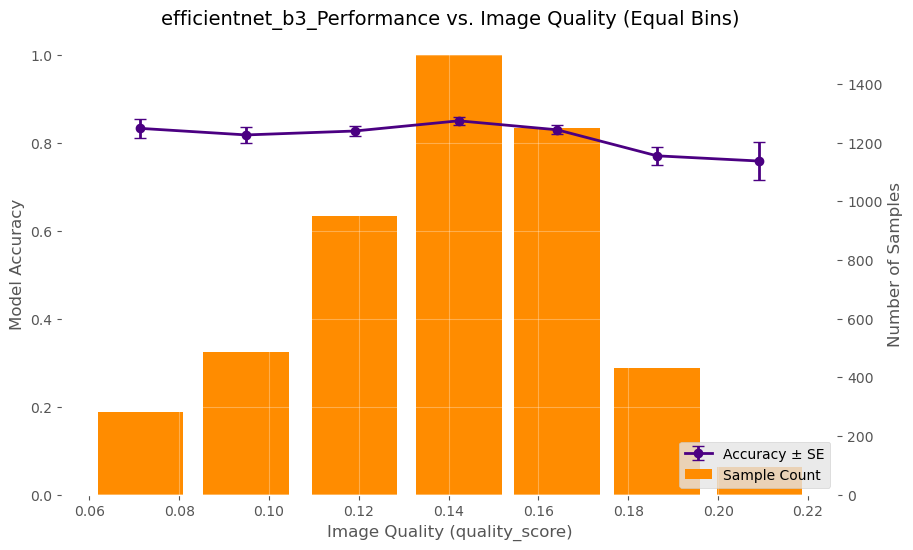

In [22]:
# 11. Performance vs. Image Quality

if PREDICTIONS_PATH.exists():
    manifest_path = PROCESSED_DATA_DIR / "manifest.csv"
    if manifest_path.exists():
        manifest = pd.read_csv(manifest_path)

        plot_performance_vs_quality(
            results_df,
            manifest,
            quality_col="quality_score",
            save_folder="evaluation",
            title_prefix=f"{MODEL_NAME}_",
            min_samples=50,
        )
        plt.show()
    else:
        logger.warning("Manifest not found. Cannot perform quality correlation analysis.")